# Vollständige Orthonormalsysteme

## Von Gaußfunktionen zu Hermite-Funktionen und numerischen Näherungen

Im Folgenden betrachten wir, wie sich eine Funktion durch eine Summe einfacher Funktionen darstellen lässt. 

Wir betrachten für ein **festes** $\beta>0$ die Funktionen

$$
g_n(x)=x^n e^{-\beta x^2},\qquad n=0,1,2,\ldots,\qquad x\in\mathbb R.
$$

Die Gaußfunktion sorgt dafür, dass jede dieser Funktionen für große $|x|$ abklingt und quadratintegrabel ist. Mit steigender Potenz entstehen immer neue Funktionen, die die reele Achse im gewissen Sinne "ausfüllen". Jede endliche Auswahl $g_0,\ldots,g_{N-1}$ ist linear unabhängig. Dies sieht man, wenn man eine Linearkombination $\sum_{n=0}^{N-1} c_n g_n(x)$ betrachtet, die identisch null ist. Nach Division durch die überall positive Gaußfunktion bleibt eine Linearkombination von Monomen, die nur bei verschwindenden Koeffizienten identisch null ist!

Wir arbeiten im Hilbertraum $L^2(\mathbb R)$ mit dem Skalarprodukt in Dirac-Notation

$$
\langle u\mid v\rangle=\int_{-\infty}^{\infty}u(x)^*v(x)\,dx,
\qquad
\|u\|_2^2=\langle u\mid u\rangle<\infty.
$$

Funktionen, die sich nur auf einer Menge vom Maß null unterscheiden, stellen hier denselben Vektor dar. Insbesondere beeinflusst der Wert an einem einzelnen Punkt weder Norm noch Skalarprodukt.

**Linear unabhängig bedeutet noch nicht orthogonal.** Zwar verschwinden wegen der Parität alle Überlappungen mit ungeradem $m+n$, aber beispielsweise gilt

$$
\langle g_0\mid g_2\rangle
=\int_{-\infty}^{\infty}x^2e^{-2\beta x^2}\,dx
=\frac{\sqrt\pi}{2(2\beta)^{3/2}}>0.
$$

## 2. Orthogonalisierung nach Gram–Schmidt

Wie bei gewöhnlichen Vektoren ziehen wir von jeder neuen Funktion ihre Projektionen auf die bereits konstruierten Richtungen ab:

$$
r_n=g_n-\sum_{m=0}^{n-1}\phi_m\langle\phi_m\mid g_n\rangle,
\qquad
\phi_n=\frac{r_n}{\|r_n\|_2}.
$$

Für $n=0$ ist die Summe leer. Damit gilt $\langle\phi_m\mid \phi_n\rangle=\delta_{mn}$. **Orthogonalisieren** entfernt die Überlappungen; **Normieren** setzt anschließend jede Norm auf eins.

### Die ersten Schritte von Hand

Mit

$$
I_0=\int e^{-2\beta x^2}\,dx=\sqrt{\frac{\pi}{2\beta}},
\qquad
\frac{I_2}{I_0}=\frac{1}{4\beta},
\qquad
\frac{I_4}{I_2}=\frac{3}{4\beta},
$$

wobei alle Integrale über $\mathbb R$ laufen und $I_k=\int x^k e^{-2\beta x^2}\,dx$, erhalten wir

$$
\begin{aligned}
r_0(x)&=e^{-\beta x^2},\\
r_1(x)&=xe^{-\beta x^2},\\
r_2(x)&=\left(x^2-\frac{1}{4\beta}\right)e^{-\beta x^2},\\
r_3(x)&=\left(x^3-\frac{3x}{4\beta}\right)e^{-\beta x^2}.
\end{aligned}
$$

Zum Beispiel muss von $g_2$ nur die Projektion auf die gerade Funktion $\phi_0$ abgezogen werden; die Projektion auf die ungerade Funktion $\phi_1$ ist null. Entsprechend überlappt $g_3$ unter den vorherigen Funktionen nur mit $\phi_1$.

In jedem Schritt bleibt der aufgespannte Raum erhalten:

$$
\operatorname{span}\{g_0,\ldots,g_{N-1}\}
=\operatorname{span}\{\phi_0,\ldots,\phi_{N-1}\}.
$$

Wir ändern also die Basis, nicht die in diesem Raum darstellbaren Funktionen. Ob die unendliche Familie **vollständig** ist, ist eine zusätzliche Frage.

### Ein kleines numerisches Beispiel

Wir wählen $\beta=1/2$ und orthogonalisieren die ersten sechs Funktionen. Die Integrale ersetzen wir hier durch die Simpson-Regel auf einem feinen Gitter. Das Intervall reicht in der skalierten Koordinate $\sqrt{2\beta}\,x$ von $-8$ bis $8$; für diese niedrigen Ordnungen sind die ausgelassenen Gaußschwänze vernachlässigbar.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson, quad_vec

plt.rcParams.update({"font.size": 12, "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False})
beta = 0.5
x = np.linspace(-8, 8, 2001) / np.sqrt(2 * beta)
gaussians = np.array([x**n * np.exp(-beta * x**2) for n in range(6)])

In [2]:
orthogonal = []
for g in gaussians:
    residual = g.copy()
    for q in orthogonal:
        residual -= simpson(q * residual, x=x) * q
    residual /= np.sqrt(simpson(residual**2, x=x))
    orthogonal.append(residual)
orthogonal = np.array(orthogonal)

Der innere Schleifendurchlauf verwendet jeweils den aktuellen Rest; dies ist die modifizierte Form des Gram–Schmidt-Verfahrens. Für die hier reellen Funktionen benötigen wir keine komplexe Konjugation im Code. Die folgende Abbildung zeigt die ersten vier Funktionen vor und nach der Orthogonalisierung.

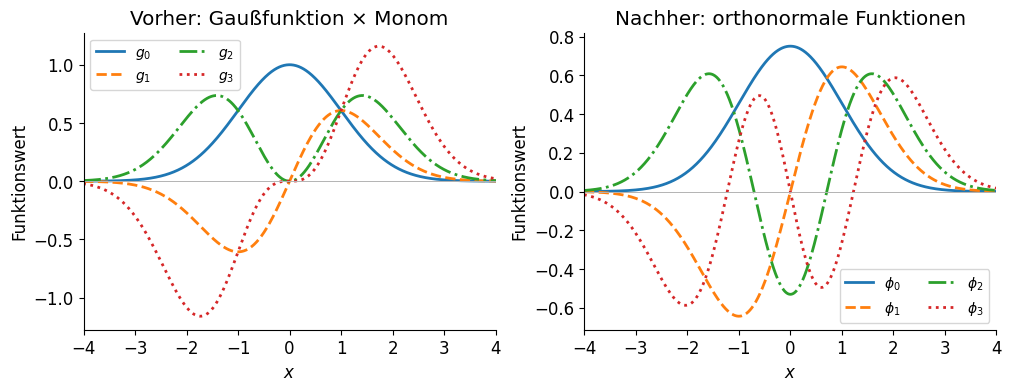

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for n, style in enumerate(["-", "--", "-.", ":"]):
    axes[0].plot(x, gaussians[n], style, label=fr"$g_{n}$")
    axes[1].plot(x, orthogonal[n], style, label=fr"$\phi_{n}$")
for ax, title in zip(axes, ["Vorher: Gaußfunktion × Monom",
                           "Nachher: orthonormale Funktionen"]):
    ax.set(xlim=(-4 / np.sqrt(2 * beta), 4 / np.sqrt(2 * beta)),
           xlabel="$x$", ylabel="Funktionswert", title=title)
    ax.axhline(0, color="0.7", lw=0.7)
    ax.legend(ncol=2, fontsize=10)
plt.show()

Die Orthogonalisierung verändert die Form der Funktionen, erhält aber ihre gerade oder ungerade Parität. Die Normierung bezieht sich auf das Integral des **Quadrats**, nicht auf die Höhe des Maximums.

## 3. Das Ergebnis: Hermite-Funktionen

Jede orthogonalisierte Funktion ist weiterhin ein Polynom mal derselben Gaußfunktion. Für die Polynome entsteht daher das Gewicht $e^{-2\beta x^2}$:

$$
\langle p_m e^{-\beta x^2}\mid p_n e^{-\beta x^2}\rangle
=\int_{-\infty}^{\infty}p_m(x)p_n(x)e^{-2\beta x^2}\,dx.
$$

Mit $y=\sqrt{2\beta}\,x$ wird daraus das Gewicht $e^{-y^2}$. Die dazugehörigen **Hermite-Polynome in der Physikerkonvention** sind

$$
H_0(y)=1,\quad H_1(y)=2y,\quad H_2(y)=4y^2-2,\quad H_3(y)=8y^3-12y.
$$

Ihre Orthogonalitätsrelation lautet

$$
\int_{-\infty}^{\infty}H_m(y)H_n(y)e^{-y^2}\,dy
=\sqrt\pi\,2^n n!\,\delta_{mn}.
$$

Nach der Rücktransformation und Normierung erhalten wir somit

$$
\boxed{
\phi_n^{(\beta)}(x)=
\frac{(2\beta/\pi)^{1/4}}{\sqrt{2^n n!}}
H_n\!\left(\sqrt{2\beta}\,x\right)e^{-\beta x^2}
}.
$$

Diese **Hermite-Funktionen** oder **Hermite-Gauß-Funktionen** sind im gewöhnlichen, ungewichteten $L^2(\mathbb R)$ orthonormal. Die Polynome allein sind dagegen bezüglich eines Gaußgewichts orthogonal. Der Faktor $\sqrt{2\beta}$ im Argument ist wesentlich: Im Skalarprodukt wird die Gaußfunktion zweimal multipliziert. Die Polynomkonvention und Normierungsintegrale sind in [NIST DLMF, Tabelle 18.3.1](https://dlmf.nist.gov/18.3#T1) zusammengestellt.

Für $\beta=1/2$ ergibt sich die bekannte Form der Eigenfunktionen des harmonischen Oszillators in dimensionslosen Koordinaten:

$$
\phi_n(x)=\frac{H_n(x)e^{-x^2/2}}{\pi^{1/4}\sqrt{2^n n!}}.
$$

### Viele Hermite-Funktionen mit einer kurzen Rekursion

Für hohe Ordnungen ist die direkte Orthogonalisierung von Monomen numerisch ungünstig: Fast linear abhängige Richtungen führen zu Auslöschung und Rundungsfehlern. Auch große Polynome und Fakultäten müssen wir nicht getrennt auswerten. Aus der Hermite-Rekursion folgt direkt

$$
\begin{aligned}
\phi_0^{(\beta)}(x)&=(2\beta/\pi)^{1/4}e^{-\beta x^2},\\
\phi_1^{(\beta)}(x)&=2\sqrt\beta\,x\phi_0^{(\beta)}(x),\\
\phi_{n+1}^{(\beta)}(x)&=
2\sqrt{\frac{\beta}{n+1}}\,x\phi_n^{(\beta)}(x)
-\sqrt{\frac{n}{n+1}}\,\phi_{n-1}^{(\beta)}(x).
\end{aligned}
$$

Die Funktion unten liefert die ersten $N\geq1$ Funktionen, also die Ordnungen $0,\ldots,N-1$. Sie akzeptiert sowohl einzelne $x$-Werte als auch ein Gitter.

In [4]:
def hermite_functions(x, N, beta=0.5):
    '''Die ersten N normierten Hermite-Funktionen für beta > 0.'''
    x = np.asarray(x)
    values = [(2 * beta / np.pi)**0.25 * np.exp(-beta * x**2)]
    if N > 1:
        values.append(2 * np.sqrt(beta) * x * values[0])
    for n in range(1, N - 1):
        next_value = (2 * np.sqrt(beta / (n + 1)) * x * values[n]
                      - np.sqrt(n / (n + 1)) * values[n - 1])
        values.append(next_value)
    return np.array(values)

### Stimmen Gram–Schmidt und Rekursion überein?

Wir vergleichen die ersten sechs Funktionen auf demselben Gitter und berechnen ihre Überlappungsmatrix. Kleine Abweichungen von null beziehungsweise der Einheitsmatrix entstehen durch die numerische Integration und endliche Rechengenauigkeit.

In [5]:
phi = hermite_functions(x, 6, beta)
overlap = np.array([[simpson(u * v, x=x) for v in phi] for u in phi])
print(f"Gram–Schmidt vs. Hermite: {np.max(np.abs(orthogonal - phi)):.2e}")
print(f"Abweichung von der Einheitsmatrix: {np.max(np.abs(overlap - np.eye(6))):.2e}")

Gram–Schmidt vs. Hermite: 8.74e-16
Abweichung von der Einheitsmatrix: 4.44e-16


Die Übereinstimmung prüft die niedrigen Ordnungen unserer Implementierung. Sie ist **kein numerischer Beweis der Vollständigkeit** einer unendlichen Familie.

## 4. Eine Stufenfunktion entwickeln

Wir wählen eine Stufenfunktion mit endlicher Breite, also einen Rechteckpuls:

$$
f(x)=\begin{cases}
1,&0<x<1,\\
0,&x<0\ \text{oder}\ x>1.
\end{cases}
$$

An den beiden Sprungstellen setzen wir für die Darstellung $f(0)=f(1)=1/2$. Diese Einzelwerte haben keinen Einfluss auf die Entwicklung. Es gilt $\|f\|_2^2=1$.

**Warum eine endliche Stufe?** Die Heaviside-Funktion $\Theta(x)$ bleibt für alle $x>0$ gleich eins und liegt deshalb nicht in $L^2(\mathbb R)$. Der Rechteckpuls $\Theta(x)-\Theta(x-1)$ gehört dagegen zu unserem Funktionenraum. Auf einem endlichen Intervall wäre auch eine einzelne Heaviside-Stufe quadratintegrabel; die hier verwendeten Hermite-Funktionen wären mit dem auf dieses Intervall beschränkten Skalarprodukt allerdings nicht mehr orthonormal.

### Koeffizienten durch Projektion

Mit den ersten $N$ Basisfunktionen bilden wir

$$
f_N(x)=\sum_{n=0}^{N-1}c_n\phi_n^{(\beta)}(x),
\qquad
c_n=\langle\phi_n^{(\beta)}\mid f\rangle
=\int_0^1\phi_n^{(\beta)}(x)\,dx.
$$

Die Integrationsgrenzen sind genau die Sprungstellen; der zu integrierende Ausdruck ist innerhalb dieses Intervalls glatt. `quad_vec` berechnet alle Koeffizienten gleichzeitig durch adaptive Quadratur. $N$ bezeichnet im gesamten Beispiel die **Anzahl der Funktionen**, nicht die höchste Ordnung.

In [6]:
orders = [4, 16, 64, 256]
N_max = max(orders)
coefficients, quadrature_error = quad_vec(
    lambda t: hermite_functions(t, N_max, beta), 0, 1,
    epsabs=1e-11, epsrel=1e-11,
)
print(f"Geschätzter Quadraturfehler des Koeffizientenvektors: {quadrature_error:.2e}")

Geschätzter Quadraturfehler des Koeffizientenvektors: 1.09e-13


### Wie verändert sich die Näherung?

Die Koeffizienten werden einmal berechnet. Für verschiedene Basisgrößen schneiden wir denselben Vektor nach $N$ Einträgen ab. Die schwarze Linie zeigt die Zielstufe, die blaue Kurve ihre endliche Hermite-Entwicklung. Alle vier Teilbilder verwenden dieselben Achsengrenzen.

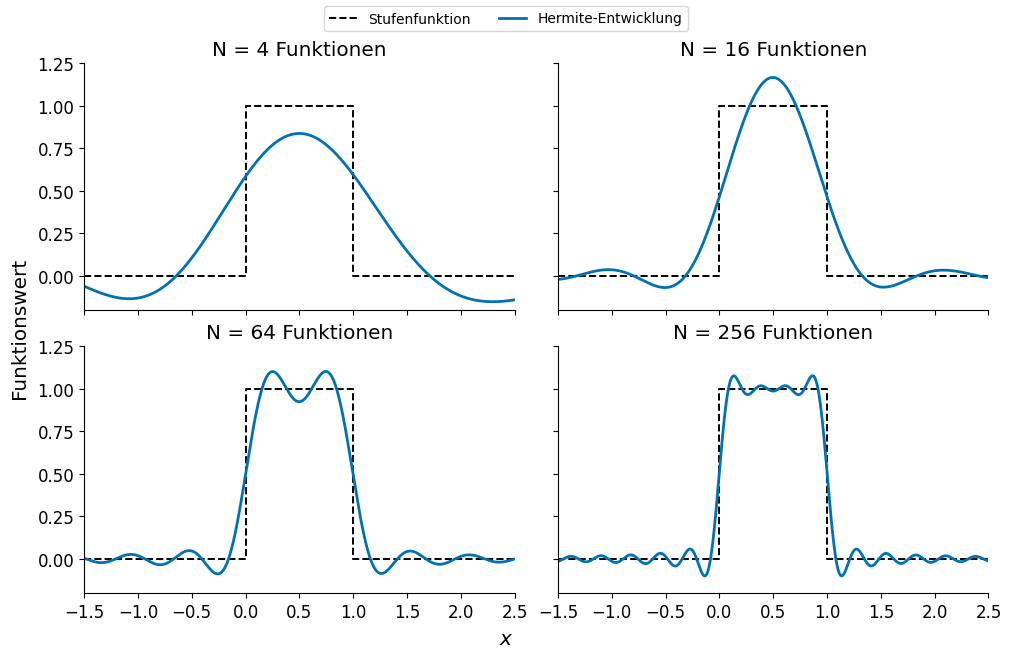

In [7]:
x_plot = np.linspace(-1.5, 2.5, 2001)
basis = hermite_functions(x_plot, N_max, beta)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True,
                         sharey=True, layout="constrained")
for ax, N in zip(axes.flat, orders):
    approximation = coefficients[:N] @ basis[:N]
    ax.plot([-1.5, 0, 0, 1, 1, 2.5], [0, 0, 1, 1, 0, 0],
            "k--", lw=1.4, label="Stufenfunktion")
    ax.plot(x_plot, approximation, color="#0072B2", label="Hermite-Entwicklung")
    ax.set(title=f"N = {N} Funktionen", xlim=(-1.5, 2.5), ylim=(-0.2, 1.25))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=10, loc="outside upper center", ncol=2)
fig.supxlabel("$x$")
fig.supylabel("Funktionswert")
plt.show()

Mit mehr Funktionen werden die Übergänge schmaler und das Plateau besser aufgelöst. In der Nähe der Sprünge bleiben Über- und Unterschwinger sichtbar. Solche Gibbs-artigen Oszillationen widersprechen einer abnehmenden **integrierten** Abweichung nicht.

Jede endliche Hermite-Summe ist glatt. Eine Folge stetiger Funktionen kann auf einem Intervall, das einen Sprung enthält, nicht gleichmäßig gegen diese unstetige Stufenfunktion konvergieren. „Genauer“ muss deshalb durch ein geeignetes Fehlermaß präzisiert werden; es bedeutet hier nicht, dass der Fehler an jedem Punkt monoton abnimmt.

### Den Fehler auf der ganzen reellen Achse messen

Aus der Orthonormalität und der Wahl $c_n=\langle\phi_n\mid f\rangle$ folgt bereits für jede endliche Projektion

$$
\begin{aligned}
\|f-f_N\|_2^2
&=\|f\|_2^2-2\operatorname{Re}\langle f_N\mid f\rangle+\|f_N\|_2^2\\
&=\|f\|_2^2-\sum_{n=0}^{N-1}|c_n|^2
=1-\sum_{n=0}^{N-1}|c_n|^2.
\end{aligned}
$$

Diese Identität braucht noch keine Vollständigkeit. Sie berücksichtigt auch die Anteile der Näherung **außerhalb des gezeichneten Fensters**. Wegen $\|f\|_2=1$ ist der absolute $L^2$-Fehler hier zugleich der relative Fehler. Die Ergebnisse sind bis auf den kleinen Quadratur- und Rundungsfehler numerisch bestimmt.

In [8]:
squared_error = 1 - np.cumsum(np.abs(coefficients)**2)
error = np.sqrt(squared_error)
print("  N     L²-Fehler")
for N in orders:
    print(f"{N:3d}     {error[N - 1]:.6f}")

  N     L²-Fehler
  4     0.499899
 16     0.313887
 64     0.227178
256     0.165744


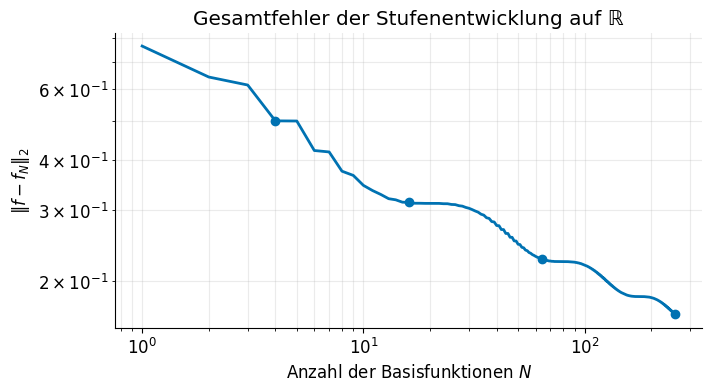

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax.loglog(np.arange(1, N_max + 1), error, color="#0072B2")
ax.scatter(orders, error[np.array(orders) - 1], color="#0072B2", zorder=3)
ax.set(xlabel="Anzahl der Basisfunktionen $N$", ylabel=r"$\|f-f_N\|_2$",
       title="Gesamtfehler der Stufenentwicklung auf ℝ")
ax.grid(alpha=0.25, which="both")
plt.show()

Für $\beta=1/2$ sinkt der Fehler von etwa **0,500 bei 4 Funktionen** auf **0,166 bei 256 Funktionen**. Er nimmt monoton ab, aber die Konvergenz der unstetigen Zielstufe ist langsam. Ein scharf aussehendes Plateau allein wäre daher kein ausreichender Genauigkeitsnachweis.

Der geschätzte Quadraturfehler oben ist wesentlich kleiner als diese Projektionsfehler. Genauere Koeffizienten können die fehlenden Basisfunktionen nicht ersetzen. Umgekehrt ist eine größere Basis nur dann hilfreich, wenn die Koeffizienten und Basisfunktionen ausreichend genau berechnet werden.

## 5. Was bedeutet Vollständigkeit?

Ein Orthonormalsystem $\{\phi_n\}_{n=0}^{\infty}$ heißt **vollständig in einem Hilbertraum $\mathcal H$**, wenn sein linearer Spann dicht in $\mathcal H$ liegt: Zu jedem $f\in\mathcal H$ und jedem $\varepsilon>0$ gibt es eine endliche Linearkombination $v$ mit $\|f-v\|<\varepsilon$.

Äquivalent dazu gibt es keinen von null verschiedenen Vektor in $\mathcal H$, der zu allen $\phi_n$ orthogonal ist. Vollständigkeit ist somit immer eine Aussage über einen **bestimmten Raum und seine Norm**.

Für die Hermite-Funktionen gilt der mathematische Satz

$$
\overline{\operatorname{span}\{\phi_0^{(\beta)},\phi_1^{(\beta)},\ldots\}}
=L^2(\mathbb R)\qquad\text{für jedes feste }\beta>0.
$$

Die Vollständigkeit der Hermite-Polynome im Raum mit Gewicht $e^{-y^2}$ geht durch Multiplikation mit $e^{-y^2/2}$ und Skalierung der Koordinate in diese Aussage über. Die Multiplikation erhält dabei die Norm, denn $\int |p(y)e^{-y^2/2}|^2dy=\int|p(y)|^2e^{-y^2}dy$; sie bildet den gewichteten Raum auf $L^2(\mathbb R)$ ab. Siehe die Aussage zur Entwicklung von $L^2$-Funktionen in [NIST DLMF, Abschnitt 18.18(i)](https://dlmf.nist.gov/18.18#i). Wir verwenden diesen Satz; die endlichen numerischen Rechnungen illustrieren ihn, beweisen ihn aber nicht.

Da Gram–Schmidt jeden endlichen Spann erhält, ist auch die ursprüngliche Familie $\{x^n e^{-\beta x^2}\}$ vollständig. **Orthonormalität allein reicht dagegen nicht:** Die Teilfamilie $\phi_0,\phi_2,\phi_4,\ldots$ ist orthonormal, enthält aber nur gerade Funktionen und kann keine von null verschiedene ungerade Funktion approximieren.

### Die endliche Entwicklung ist die beste Näherung in ihrem Raum

Sei $V_N=\operatorname{span}\{\phi_0,\ldots,\phi_{N-1}\}$. Für die Projektion $f_N$ gilt $f-f_N\perp V_N$. Für jedes $v\in V_N$ liefert der Satz des Pythagoras deshalb

$$
\|f-v\|^2=\|f-f_N\|^2+\|f_N-v\|^2
\geq\|f-f_N\|^2.
$$

Die Projektionskoeffizienten liefern also die **beste Näherung in der Hilbertraumnorm** innerhalb von $V_N$. Fügt man eine weitere orthonormale Funktion hinzu, gilt

$$
\|f-f_{N+1}\|^2=\|f-f_N\|^2-|c_N|^2.
$$

Der Fehler kann bei verschachtelten Räumen nicht wachsen; er bleibt gleich, wenn der neue Koeffizient null ist. Erst die Vollständigkeit garantiert zusätzlich, dass der Grenzwert des Fehlers null ist:

$$
f=\sum_{n=0}^{\infty}c_n\phi_n
\quad\text{im Sinn der Normkonvergenz},
\qquad
\|f\|^2=\sum_{n=0}^{\infty}|c_n|^2.
$$

Die zweite Gleichung ist die **Parseval-Identität**. Insbesondere ist der quadratische Fehler einer abgeschnittenen vollständigen Entwicklung gleich $\sum_{n=N}^{\infty}|c_n|^2$.

### Konsequenzen für numerische Approximationen

- **Raum, Skalarprodukt und Norm gehören zur Aufgabenstellung.** Eine Basis kann in einem Raum vollständig und für eine andere Aufgabenstellung ungeeignet sein. Aus $L^2$-Konvergenz folgt im Allgemeinen weder punktweise noch gleichmäßige Konvergenz.
- **Vollständigkeit ist eine Aussage über den Grenzfall.** Sie garantiert beliebige Genauigkeit bei genügend vielen Funktionen, aber keine bestimmte Konvergenzgeschwindigkeit oder kleine erforderliche Basisgröße.
- **Orthonormalität vereinfacht die Rechnung.** Koeffizienten erhält man durch einzelne Skalarprodukte. In einer nichtorthogonalen Basis muss man stattdessen das Überlappungssystem $S a=b$ mit $S_{mn}=\langle g_m\mid g_n\rangle$ und $b_m=\langle g_m\mid f\rangle$ lösen; dessen Konditionierung kann die Genauigkeit begrenzen.
- **Die Basis sollte zur Zielstruktur passen.** Glattheit, räumliche Ausdehnung, Symmetrie und Randbedingungen beeinflussen die Effizienz. Alle festen $\beta>0$ liefern vollständige Hermite-Systeme, doch bei endlichem $N$ kann die Wahl von $\beta$ den Fehler stark verändern. Bei geändertem $\beta$ müssen die Koeffizienten neu berechnet werden.
- **Basisfehler und Rechenfehler sind verschieden.** Basisgröße, Quadraturgenauigkeit, Rechengebiet und Rundungsfehler müssen passend kontrolliert werden. Eine gute Kurve auf einem begrenzten Gitter genügt dazu nicht.
- **Die relevante physikalische Größe bestimmt die nötige Konvergenz.** Eine kleine $L^2$-Abweichung der Wellenfunktion allein garantiert keine genaue Ableitung oder kinetische Energie. Dafür sind zusätzliche Regularität und Konvergenz in einer stärkeren Norm erforderlich; die hier betrachtete Stufenfunktion besitzt Sprünge und keine quadratintegrable schwache Ableitung.

Eine vollständige Basis schafft damit die mathematische Möglichkeit systematischer Verbesserung. Ob eine endliche Rechnung bereits genau genug ist, entscheidet ein zur Fragestellung passendes Konvergenzkriterium.